## 1. Imports and shared code

In [1]:
import sys
import time
from pathlib import Path
from itertools import product
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.windowed import rqa_frame, rrc_frame, window_surrogates, beta_distance

## 2. Data

In [2]:
# Load FRED monthly series
DATA_DIR = Path("../../data/raw/fred")  # relative to notebooks/02_macro/, where this notebook lives

def load_csv(name: str) -> pd.Series:
    df = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["observation_date"], index_col="observation_date")
    return df[name].astype(float)

cpi = load_csv("CPIAUCSL")
unrate = load_csv("UNRATE")
fedfunds = load_csv("FEDFUNDS")

for s in (cpi, unrate, fedfunds):
    print(f"{s.name:9s} {s.index.min().date()} to {s.index.max().date()}  n={len(s)}  missing={s.isna().sum()}")

CPIAUCSL  1947-01-01 to 2026-09-01  n=957  missing=1
UNRATE    1948-01-01 to 2026-09-01  n=945  missing=1
FEDFUNDS  1954-07-01 to 2026-09-01  n=867  missing=0


In [3]:
# Impute October 2025 as Bureau of labor stats did not collect CPI or household-survey data during the shutdown

cpi_m, unrate_m, fedfunds_m = (s.asfreq("MS") for s in (cpi, unrate, fedfunds))

cpi_imputed = cpi_m.isna()
unrate_imputed = unrate_m.isna()

print("Imputing CPI at:", list(cpi_m.index[cpi_imputed].date))
print("Imputing UNRATE at:", list(unrate_m.index[unrate_imputed].date))
assert not fedfunds_m.isna().any()

cpi_clean = np.exp(np.log(cpi_m).interpolate(method="linear", limit_area="inside"))  # geometric for a price level
unrate_clean = unrate_m.interpolate(method="linear", limit_area="inside")
fedfunds_clean = fedfunds_m

print(pd.DataFrame({"CPIAUCSL": cpi_clean, "UNRATE": unrate_clean}).loc["2025-09":"2025-11"])

Imputing CPI at: [datetime.date(2025, 10, 1)]
Imputing UNRATE at: [datetime.date(2025, 10, 1)]


,CPIAUCSL,UNRATE
observation_date,,
2025-09-01,324.245000,4.40
2025-10-01,324.653742,4.45
2025-11-01,325.063000,4.50


In [4]:
# CPI level turned to YoY inflation, on the full CPI history (1947-), thus no lost months at the 1954 start
# YoY inflation instead of MoM inflation, avoiding overly noisy periods 
inflation = (100 * (np.log(cpi_clean) - np.log(cpi_clean.shift(12)))).rename("INFLATION")

# A YoY value is imputed if either of its two CPI inputs was imputed
inflation_imputed = cpi_imputed | cpi_imputed.shift(12, fill_value=False)

inflation = inflation.dropna()
inflation_imputed = inflation_imputed.loc[inflation.index]
print(f"INFLATION {inflation.index.min().date()} to {inflation.index.max().date()}  n={len(inflation)}")

INFLATION 1948-01-01 to 2026-09-01  n=945


In [5]:
# Common window, checks
macro = pd.concat([inflation, unrate_clean, fedfunds_clean], axis=1, join="inner")
macro["IMPUTED"] = (inflation_imputed | unrate_imputed).loc[macro.index]

assert macro.index.is_monotonic_increasing and macro.index.is_unique
assert len(macro.asfreq("MS")) == len(macro), "gap in monthly index"
assert not macro.isna().any().any(), "NaN left after cleaning"

print(f"{macro.index.min().date()} to {macro.index.max().date()}  n={len(macro)}")
print("Imputed rows:", list(macro.index[macro["IMPUTED"]].date))
macro.head()

1954-07-01 to 2026-09-01  n=867
Imputed rows: [datetime.date(2025, 10, 1)]


,INFLATION,UNRATE,FEDFUNDS,IMPUTED
observation_date,,,,
1954-07-01,0.260951,5.8,0.80,False
1954-08-01,0.000000,6.0,1.22,False
1954-09-01,-0.297952,6.1,1.07,False
1954-10-01,-0.857095,5.7,0.85,False
1954-11-01,-0.261048,5.3,0.83,False


## 3. Target and evaluation calendar

In [6]:
y = (macro.INFLATION.shift(-1) > macro.INFLATION).astype(int).iloc[:-1]
# A label touches an imputed month if t or t+1 is imputed; such rows are never scored
label_imputed = (macro.IMPUTED | macro.IMPUTED.shift(-1, fill_value=False)).iloc[:-1]


def blocks(first_year, last_year):
    for year in range(first_year, last_year + 1):
        train = y.index < pd.Timestamp(year, 1, 1)
        test = y.index.year == year
        assert y.index[train].max() < y.index[test].min()
        yield train, test


def scored_rows(first_year, last_year):
    test = np.zeros(len(y), bool)
    for _, t in blocks(first_year, last_year):
        test |= t
    return test & ~label_imputed.to_numpy()


print(f"screening rows: {scored_rows(1975, 1999).sum()}, final rows: {scored_rows(2000, 2026).sum()}")

screening rows: 300, final rows: 318


## 4. Windowed β-RP features

Delete `data/processed/rp_screening/beta/` after changing feature code (and `rp_screening/iaaft/` after changing surrogate code).

In [7]:
CACHE_DIR = Path("../../data/processed/rp_screening/beta")
SURR_DIR = Path("../../data/processed/rp_screening/iaaft")  # shared with the Euclidean notebook
SERIES = {"cpi": "INFLATION", "un": "UNRATE", "fed": "FEDFUNDS"}
JOINTS = {"jun": ("cpi", "un"), "jfed": ("cpi", "fed")}
RQA_KEEP = ["DET", "L", "ENTR", "LAM", "DET3_DET2", "K2_lines"]
RRC_KEEP = ["RRc", "dRRc"]
THEILER, RRC_DELTA, N_SURR = 1, 0.05, 19
BETAS = [-5.0, -2.0, -1.0, -0.5, 0.5, 1.0, 2.0, 5.0]
KEYS = ["W", "m", "tau", "rr", "beta"]
FEATURE_COLS = ([f"{p}_{k}" for p in SERIES for k in RQA_KEEP + RRC_KEEP]
                + [f"{p}_{k}" for p in JOINTS for k in ["RR"] + RQA_KEEP + RRC_KEEP])


def rp_features(W, m, tau, rr, beta, data=macro) -> pd.DataFrame:
    df = rqa_frame(data, SERIES, JOINTS, W, m, tau, rr, partial(beta_distance, beta=beta), THEILER)
    # ε comes from the target rate, so single-series RR carries no information; ties at ε (m = 1) leave std up to ~6e-4
    assert df["cpi_RR"].std() < 1e-3
    return df


def rrc_features(W, m, tau, beta, data=macro, surrogates=None) -> pd.DataFrame:
    if surrogates is None:
        surrogates = window_surrogates(data, SERIES, W, N_SURR)
    return rrc_frame(data, SERIES, JOINTS, W, m, tau, partial(beta_distance, beta=beta), surrogates,
                     THEILER, RRC_DELTA)


def cached(path, build, load=True):
    if path.exists():
        return pd.read_pickle(path) if load else None
    path.parent.mkdir(parents=True, exist_ok=True)
    obj = build()
    tmp = path.with_suffix(".tmp")
    pd.to_pickle(obj, tmp)
    tmp.replace(path)
    return obj if load else None


def load_surrogates(W, load=True):
    return cached(SURR_DIR / f"W{W}_n{N_SURR}.pkl", lambda: window_surrogates(macro, SERIES, W, N_SURR), load)


def load_rrc(W, m, tau, beta, load=True):
    return cached(CACHE_DIR / "rrc" / f"W{W}_m{m}_tau{tau}_b{beta:g}.pkl",
                  lambda: rrc_features(W, m, tau, beta, surrogates=load_surrogates(W)), load)


def load_rqa(W, m, tau, rr, beta, load=True):
    return cached(CACHE_DIR / "rqa" / f"W{W}_m{m}_tau{tau}_rr{rr:.2f}_b{beta:g}.pkl",
                  lambda: rp_features(W, m, tau, rr, beta), load)


def load_features(W, m, tau, rr, beta) -> pd.DataFrame:
    return load_rqa(W, m, tau, rr, beta).join(load_rrc(W, m, tau, beta))[FEATURE_COLS]


rp_grid = [(W, m, tau, rr, beta)
           for W, m, tau, rr, beta in product([24, 36, 60, 120], [1, 2, 3, 4], [1, 3, 6, 12], [0.05, 0.10, 0.20], BETAS)
           if (m > 1 or tau == 1) and W - (m - 1) * tau >= 12]
assert len(rp_grid) == 1152
rrc_keys = sorted({(W, m, tau, beta) for W, m, tau, _, beta in rp_grid}, key=lambda k: -k[0])

In [8]:
# Phases, so no two jobs build the same cache file; RRc does not depend on rr
t0 = time.perf_counter()
Parallel(n_jobs=-1)(delayed(load_surrogates)(W, load=False) for W in sorted({k[0] for k in rrc_keys}))
Parallel(n_jobs=-1)(delayed(load_rrc)(*k, load=False) for k in rrc_keys)
Parallel(n_jobs=-1)(delayed(load_rqa)(*cfg, load=False) for cfg in rp_grid)
features = {cfg: load_features(*cfg) for cfg in rp_grid}
print(f"{len(features)} RP configurations in {time.perf_counter() - t0:.0f} s")

C:\Users\skous\personal knowledge base\RQA Research\RecPlay\src\recplay\rqa.py:39: RuntimeWarning: invalid value encountered in scalar divide
  det = lambda lmin: diag[diag >= lmin].sum() / pts
C:\Users\skous\personal knowledge base\RQA Research\RecPlay\src\recplay\rqa.py:39: RuntimeWarning: invalid value encountered in scalar divide
  det = lambda lmin: diag[diag >= lmin].sum() / pts
C:\Users\skous\personal knowledge base\RQA Research\RecPlay\src\recplay\rqa.py:39: RuntimeWarning: invalid value encountered in scalar divide
  det = lambda lmin: diag[diag >= lmin].sum() / pts
C:\Users\skous\personal knowledge base\RQA Research\RecPlay\src\recplay\rqa.py:39: RuntimeWarning: invalid value encountered in scalar divide
  det = lambda lmin: diag[diag >= lmin].sum() / pts
C:\Users\skous\personal knowledge base\RQA Research\RecPlay\src\recplay\rqa.py:39: RuntimeWarning: invalid value encountered in scalar divide
  det = lambda lmin: diag[diag >= lmin].sum() / pts
C:\Users\skous\personal knowle

1152 RP configurations in 4175 s


## 5. RRc report

In [9]:
rrc_choices = pd.Series({
    "Theiler w": THEILER,
    "edge fraction δ": RRC_DELTA,
    "neighbourhood": "8-neighbour",
    "distance": "symmetric β-divergence of exp(z) states",
    "joint RPs": "pairs ordered by the max of their per-series Ω-ranks",
    "surrogate": f"IAAFT, {N_SURR} per window, seeded by (W, end month, series)",
    "statistic": "dRRc = RRc − mean surrogate RRc",
})
print(rrc_choices.to_string())

rows = []
for k in rrc_keys:
    df = load_rrc(*k)
    for p in [*SERIES, *JOINTS]:
        rows.append({**dict(zip(["W", "m", "tau", "beta"], k)), "rp": p,
                     "RRc": df[f"{p}_RRc"].median(), "RRc_sur": df[f"{p}_RRc_sur"].median(),
                     "dRRc": df[f"{p}_dRRc"].median(),
                     "below all surrogates": (df[f"{p}_RRc_pct"] == 0).mean(),
                     "above all surrogates": (df[f"{p}_RRc_pct"] == 1).mean()})
rrc_report = pd.DataFrame(rows).groupby(["rp", "beta", "W"])[["RRc", "RRc_sur", "dRRc", "below all surrogates", "above all surrogates"]].mean()
rrc_report

Theiler w                                                          1
edge fraction δ                                                 0.05
neighbourhood                                            8-neighbour
distance                     symmetric β-divergence of exp(z) states
joint RPs          pairs ordered by the max of their per-series Ω...
surrogate          IAAFT, 19 per window, seeded by (W, end month,...
statistic                            dRRc = RRc − mean surrogate RRc


RRc   RRc_sur  ...  below all surrogates  above all surrogates
rp  beta W                        ...                                            
cpi -5.0 24   0.516350  0.359198  ...              0.015166              0.169787
         36   0.481655  0.329558  ...              0.017628              0.168470
         60   0.428149  0.288175  ...              0.019802              0.172125
         120  0.392051  0.228308  ...              0.019642              0.205368
    -2.0 24   0.406009  0.319046  ...              0.019194              0.103199
...                ...       ...  ...                   ...                   ...
un   2.0 120  0.302349  0.225472  ...              0.033114              0.105306
     5.0 24   0.685914  0.397170  ...              0.010427              0.288626
         36   0.668087  0.370096  ...              0.010817              0.253405
         60   0.583194  0.331800  ...              0.015518              0.232578
         120  0.379284  0.286449  ...              0.030852              0.131119

[160 rows x 5 columns]

## 6. Leakage check

In [10]:
CHECK = (60, 3, 3, 0.10, -2.0)
full = load_features(*CHECK)
for month in ["1980-06-01", "1995-01-01", "2020-04-01"]:
    # Only the last window plus one month: the row for `month` must not need anything else
    sub = macro.loc[:month].iloc[-(CHECK[0] + 1):]
    trunc = rp_features(*CHECK, data=sub).join(rrc_features(*CHECK[:3], CHECK[4], data=sub))[FEATURE_COLS]
    assert np.allclose(full.loc[month], trunc.loc[month], equal_nan=True), month
print("features at t depend only on the W months ending at t")

features at t depend only on the W months ending at t


## 7. Screening run

In [11]:
FEATURE_SETS = {
    "CPI": ["cpi_"],
    "CPI+UNRATE": ["cpi_", "un_"],
    "CPI+FEDFUNDS": ["cpi_", "fed_"],
    "CPI+CPI∧UNRATE": ["cpi_", "jun_"],
    "CPI+CPI∧FEDFUNDS": ["cpi_", "jfed_"],
}
SCREEN_YEARS = (1975, 1999)
FINAL_YEARS = (2000, 2026)


def make_classifier():
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=1, verbose=-1)


def select(X, feature_set):
    return X[[c for c in X.columns if c.startswith(tuple(FEATURE_SETS[feature_set]))]]


def evaluate(X, first_year, last_year):
    has = y.index.isin(X.index)
    X = X.reindex(y.index)
    pred = pd.Series(np.nan, index=y.index)
    for train, test in blocks(first_year, last_year):
        train &= has
        assert has[test].all()
        model = make_classifier().fit(X[train], y[train])
        pred[test] = model.predict_proba(X[test])[:, 1]
    rows = scored_rows(first_year, last_year)
    p, t = pred[rows], y[rows]
    return {"auc": roc_auc_score(t, p), "acc": accuracy_score(t, p >= 0.5), "n_test": int(rows.sum())}, p


def screen_one(X, cfg, feature_set):
    scores, pred = evaluate(X, *SCREEN_YEARS)
    return dict(zip(KEYS, cfg), feature_set=feature_set, **scores), pred

In [12]:
t0 = time.perf_counter()
results = Parallel(n_jobs=-1)(delayed(screen_one)(select(features[cfg], fs), cfg, fs) for cfg in rp_grid for fs in FEATURE_SETS)
screen = pd.DataFrame([r for r, _ in results])
screen_preds = {tuple(r[k] for k in KEYS + ["feature_set"]): p for r, p in results}
assert len(screen) == 5760
assert (screen.n_test == 300).all()
print(f"5760 model configurations in {time.perf_counter() - t0:.0f} s")
screen.sort_values("auc", ascending=False).head(10)

5760 model configurations in 268 s


,W,m,tau,rr,beta,feature_set,auc,acc,n_test
3244,60,3,1,0.05,-5.0,CPI+CPI∧FEDFUNDS,0.686746,0.656667,300
2726,60,1,1,0.20,-2.0,CPI+UNRATE,0.674434,0.653333,300
2687,60,1,1,0.10,-2.0,CPI+FEDFUNDS,0.665946,0.630000,300
2701,60,1,1,0.10,0.5,CPI+UNRATE,0.661417,0.633333,300
2855,60,2,1,0.20,-0.5,CPI,0.660780,0.613333,300
2686,60,1,1,0.10,-2.0,CPI+UNRATE,0.660120,0.620000,300
2685,60,1,1,0.10,-2.0,CPI,0.658869,0.626667,300
2689,60,1,1,0.10,-2.0,CPI+CPI∧FEDFUNDS,0.657389,0.653333,300
2769,60,2,1,0.05,-2.0,CPI+CPI∧FEDFUNDS,0.656183,0.640000,300
2764,60,2,1,0.05,-5.0,CPI+CPI∧FEDFUNDS,0.653839,0.646667,300


## 8. Baselines and noise band

In [20]:
persist = (macro.INFLATION.diff() > 0).astype(int).reindex(y.index)
dpi = macro.INFLATION.diff()
lagged = pd.concat({f"dpi_lag{k}": dpi.shift(k) for k in range(12)}, axis=1).join(macro[["INFLATION", "UNRATE", "FEDFUNDS"]])


def no_fit_baselines(first_year, last_year):
    majority = pd.Series(np.nan, index=y.index)
    for train, test in blocks(first_year, last_year):
        majority[test] = int(y[train].mean() > 0.5)
    rows = scored_rows(first_year, last_year)
    t = y[rows]
    return {"majority": {"auc": 0.5, "acc": accuracy_score(t, majority[rows])},
            "persistence": {"auc": roc_auc_score(t, persist[rows]), "acc": accuracy_score(t, persist[rows])}}


def chance_band(pred, labels, n=2000):
    rng = np.random.default_rng(0)
    aucs = [roc_auc_score(rng.permutation(labels.to_numpy()), pred) for _ in range(n)]
    return tuple(np.quantile(aucs, [0.025, 0.975]))


print("persistence on screening months:", no_fit_baselines(*SCREEN_YEARS)["persistence"])

persistence on screening months: {'auc': 0.6273952027672841, 'acc': 0.6366666666666667}


In [21]:
lagged_scores, lagged_pred = evaluate(lagged, *SCREEN_YEARS)
best = screen.loc[screen.auc.idxmax()]
best_pred = screen_preds[tuple(best[KEYS + ["feature_set"]])]
band_lo, band_hi = chance_band(best_pred, y[best_pred.index])

baselines_screen = pd.DataFrame({
    **no_fit_baselines(*SCREEN_YEARS),
    "lagged values": {"auc": lagged_scores["auc"], "acc": lagged_scores["acc"]},
    "best RP config": {"auc": best.auc, "acc": best.acc},
    "chance band 2.5%": {"auc": band_lo, "acc": np.nan},
    "chance band 97.5%": {"auc": band_hi, "acc": np.nan},
}).T
baselines_screen

,auc,acc
majority,0.500000,0.576667
persistence,0.627395,0.636667
lagged values,0.705976,0.673333
best RP config,0.686746,0.656667
chance band 2.5%,0.430027,NaN
chance band 97.5%,0.569391,NaN


## 9. Lagged values + best RP set

In [22]:
best_cfg = tuple(best[KEYS])
lagged_rp = lagged.join(select(features[best_cfg], best.feature_set))
lagged_rp_scores, lagged_rp_pred = evaluate(lagged_rp, *SCREEN_YEARS)


def auc_gain(p_new, p_base, n=2000):
    """AUC(p_new) - AUC(p_base) on the same months, with a 95% interval from resampling whole calendar years."""
    t = y[p_new.index]
    years = p_new.index.year
    groups = [np.flatnonzero(years == yr) for yr in np.unique(years)]
    rng = np.random.default_rng(0)
    diffs = []
    for _ in range(n):
        i = np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])
        diffs.append(roc_auc_score(t.iloc[i], p_new.iloc[i]) - roc_auc_score(t.iloc[i], p_base.iloc[i]))
    return roc_auc_score(t, p_new) - roc_auc_score(t, p_base), *np.quantile(diffs, [0.025, 0.975])


gain, gain_lo, gain_hi = auc_gain(lagged_rp_pred, lagged_pred)
# The RP set was chosen on these same months, so this gain is optimistic
print(f"best RP set: {dict(zip(KEYS, best_cfg))}, {best.feature_set}")
print(f"AUC gain over lagged values: {gain:+.3f} (95% year-block bootstrap {gain_lo:+.3f} to {gain_hi:+.3f})")
pd.DataFrame({"lagged values": lagged_scores, "lagged + best RP": lagged_rp_scores}).T

best RP set: {'W': np.int64(60), 'm': np.int64(3), 'tau': np.int64(1), 'rr': np.float64(0.05), 'beta': np.float64(-5.0)}, CPI+CPI∧FEDFUNDS
AUC gain over lagged values: +0.013 (95% year-block bootstrap -0.020 to +0.049)


,auc,acc,n_test
lagged values,0.705976,0.673333,300.0
lagged + best RP,0.719448,0.683333,300.0


## 10. Which parameters matter

,range
factor,
W,0.024946
m,0.012554
tau,0.019961
rr,0.006800
beta,0.027748
feature_set,0.005723


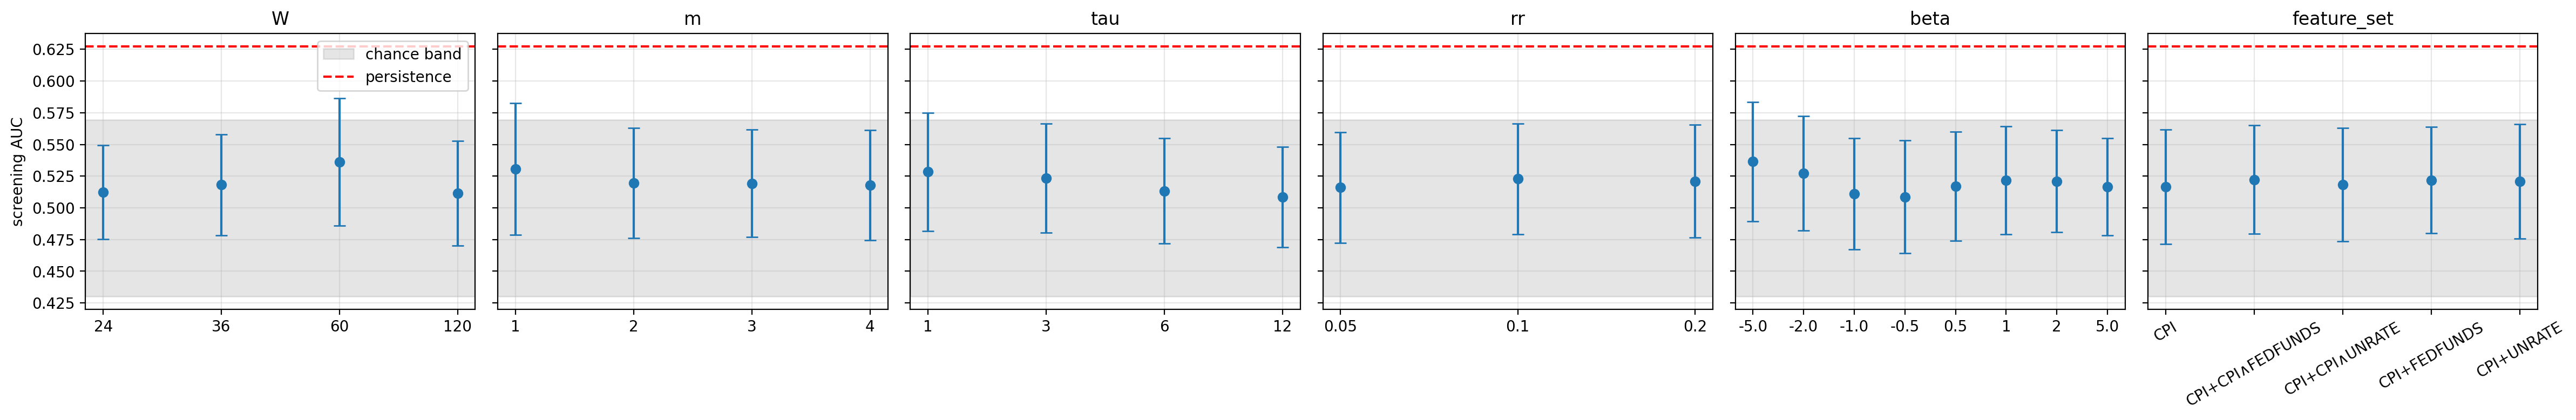

mean       std
factor      level                                
W            24                0.512174  0.037018
             36                0.518146  0.039911
             60                0.536338  0.050215
             120               0.511392  0.041174
m            1                 0.530565  0.051977
             2                 0.519686  0.043377
             3                 0.519240  0.042287
             4                 0.518011  0.043405
tau          1                 0.528417  0.046557
             3                 0.523495  0.043025
             6                 0.513388  0.041405
             12                0.508456  0.039459
rr           0.05              0.516071  0.043551
             0.1               0.522871  0.043724
             0.2               0.521057  0.044286
beta        -5.0               0.536470  0.046931
            -2.0               0.527328  0.045084
            -1.0               0.510899  0.043875
            -0.5               0.508722  0.044670
             0.5               0.517033  0.043049
             1                 0.521752  0.042711
             2                 0.520994  0.040091
             5.0               0.516799  0.038295
feature_set  CPI               0.516589  0.044914
             CPI+CPI∧FEDFUNDS  0.522312  0.042739
             CPI+CPI∧UNRATE    0.518371  0.044706
             CPI+FEDFUNDS      0.521889  0.041888
             CPI+UNRATE        0.520837  0.045165

In [23]:
FACTORS = KEYS + ["feature_set"]
marginal = pd.concat({f: screen.groupby(f).auc.agg(["mean", "std"]) for f in FACTORS}, names=["factor", "level"])
print(marginal.groupby(level="factor", sort=False)["mean"].agg(lambda s: s.max() - s.min()).rename("range"))

fig, axes = plt.subplots(1, len(FACTORS), figsize=(4 * len(FACTORS), 4), sharey=True)
for ax, f in zip(axes, FACTORS):
    g = marginal.loc[f]
    ax.errorbar(range(len(g)), g["mean"], yerr=g["std"], fmt="o", capsize=4)
    ax.set_xticks(range(len(g)), [str(v) for v in g.index], rotation=30 if f == "feature_set" else 0)
    ax.axhspan(band_lo, band_hi, color="grey", alpha=0.2, label="chance band")
    ax.axhline(baselines_screen.loc["persistence", "auc"], color="red", ls="--", label="persistence")
    ax.set_title(f)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("screening AUC")
axes[0].legend()
fig.tight_layout()
plt.show()
marginal

In [24]:
def decompose(screen):
    main = {f: pd.get_dummies(screen[f], prefix=f, prefix_sep="=", drop_first=True, dtype=float) for f in FACTORS}
    pairs = [(f, g) for i, f in enumerate(FACTORS) for g in FACTORS[i + 1 :]]
    inter = {(f, g): pd.DataFrame({f"{a}*{b}": main[f][a] * main[g][b] for a in main[f] for b in main[g]})
             for f, g in pairs}
    auc = screen.auc.to_numpy()
    ss_tot = ((auc - auc.mean()) ** 2).sum()

    def r2(terms):
        X = np.column_stack([np.ones(len(screen))] + [t.to_numpy() for t in terms])
        resid = auc - X @ np.linalg.lstsq(X, auc, rcond=None)[0]
        return 1 - (resid ** 2).sum() / ss_tot

    r2_full = r2([*main.values(), *inter.values()])
    shares = pd.Series({f: r2_full - r2([main[k] for k in FACTORS if k != f]
                                        + [inter[p] for p in pairs if f not in p]) for f in FACTORS})
    interaction_shares = pd.Series({f"{f}×{g}": r2_full - r2([*main.values()] + [inter[p] for p in pairs if p != (f, g)])
                                    for f, g in pairs})
    return shares, interaction_shares, r2_full


shares, interaction_shares, r2_full = decompose(screen)

In [25]:
meta_X = screen[KEYS].astype(float).assign(feature_set=screen.feature_set.astype("category"))
fold_r2, fold_imp = [], []
for train, test in KFold(5, shuffle=True, random_state=0).split(meta_X):
    meta = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                         random_state=0, verbose=-1).fit(meta_X.iloc[train], screen.auc.iloc[train])
    fold_r2.append(meta.score(meta_X.iloc[test], screen.auc.iloc[test]))
    fold_imp.append(permutation_importance(meta, meta_X.iloc[test], screen.auc.iloc[test],
                                           n_repeats=30, scoring="r2", random_state=0).importances)
meta_r2 = float(np.mean(fold_r2))
imp = np.concatenate(fold_imp, axis=1)
meta_importance = pd.Series(imp.mean(axis=1), index=meta_X.columns)
meta_importance_std = pd.Series(imp.std(axis=1), index=meta_X.columns)
print(f"meta-model CV R² = {meta_r2:.3f}")
pd.DataFrame({"importance": meta_importance, "std": meta_importance_std})

meta-model CV R² = 0.368


,importance,std
W,0.476939,0.037167
m,0.102387,0.012085
tau,0.244853,0.023493
rr,0.058459,0.008632
beta,0.327001,0.025891
feature_set,0.046777,0.008159


In [26]:
def verdict(screen, shares, r2_full, band, meta_importance=None) -> pd.DataFrame:
    ranges = pd.Series({f: screen.groupby(f).auc.mean().agg(lambda s: s.max() - s.min()) for f in FACTORS})
    out = pd.DataFrame({"share": shares[FACTORS], "range": ranges,
                        "meta_importance": np.nan if meta_importance is None else meta_importance.reindex(FACTORS)})
    out["matters"] = (out.share >= 0.10 * r2_full) & (out.range >= (band[1] - band[0]) / 2)
    return out


factor_verdict = verdict(screen, shares, r2_full, (band_lo, band_hi), meta_importance)
print(factor_verdict)
print(interaction_shares.sort_values(ascending=False))
print(f"R² full = {r2_full:.3f}")

,share,range,meta_importance,matters
W,0.208733,0.024946,0.476939,False
m,0.036035,0.012554,0.102387,False
tau,0.088016,0.019961,0.244853,False
rr,0.014847,0.006800,0.058459,False
beta,0.139999,0.027748,0.327001,False
feature_set,0.026344,0.005723,0.046777,False


,
W×beta,0.064705
W×tau,0.030548
tau×beta,0.019641
W×m,0.018014
W×feature_set,0.012590
m×beta,0.010231
beta×feature_set,0.006248
W×rr,0.004101
m×tau,0.002679
tau×rr,0.002340


R² full = 0.336


## 11. Final test on 2000–2026

Run once. Do not use this section to choose parameters.

In [27]:
picks = (screen.sort_values(["auc", *KEYS], ascending=[False] + [True] * len(KEYS))
         .groupby("feature_set", sort=False).head(1).set_index("feature_set").loc[list(FEATURE_SETS)])

final_rows, final_preds = {}, {}
for fs, r in picks.iterrows():
    cfg = tuple(r[KEYS])
    scores, final_preds[fs] = evaluate(select(features[cfg], fs), *FINAL_YEARS)
    assert scores["n_test"] == 318
    final_rows[fs] = {**dict(zip(KEYS, cfg)), "screen_auc": r.auc, "final_auc": scores["auc"], "final_acc": scores["acc"]}

for name, s in no_fit_baselines(*FINAL_YEARS).items():
    final_rows[name] = {"screen_auc": baselines_screen.loc[name, "auc"], "final_auc": s["auc"], "final_acc": s["acc"]}
lagged_final, lagged_final_pred = evaluate(lagged, *FINAL_YEARS)
final_rows["lagged values"] = {"screen_auc": baselines_screen.loc["lagged values", "auc"],
                               "final_auc": lagged_final["auc"], "final_acc": lagged_final["acc"]}
lagged_rp_final, lagged_rp_final_pred = evaluate(lagged_rp, *FINAL_YEARS)
final_rows["lagged + best RP"] = {**dict(zip(KEYS, best_cfg)), "screen_auc": lagged_rp_scores["auc"],
                                  "final_auc": lagged_rp_final["auc"], "final_acc": lagged_rp_final["acc"]}
gain, gain_lo, gain_hi = auc_gain(lagged_rp_final_pred, lagged_final_pred)
print(f"final AUC gain of lagged + best RP over lagged values: {gain:+.3f} ({gain_lo:+.3f} to {gain_hi:+.3f})")
best_final = final_preds[picks.auc.idxmax()]
final_lo, final_hi = chance_band(best_final, y[best_final.index])
final_rows["chance band 2.5%"] = {"screen_auc": band_lo, "final_auc": final_lo}
final_rows["chance band 97.5%"] = {"screen_auc": band_hi, "final_auc": final_hi}

final = pd.DataFrame(final_rows).T[KEYS + ["screen_auc", "final_auc", "final_acc"]]
final

final AUC gain of lagged + best RP over lagged values: -0.007 (-0.034 to +0.024)


,W,m,tau,rr,beta,screen_auc,final_auc,final_acc
CPI,60.0,2.0,1.0,0.20,-0.5,0.660780,0.466129,0.459119
CPI+UNRATE,60.0,1.0,1.0,0.20,-2.0,0.674434,0.473449,0.468553
CPI+FEDFUNDS,60.0,1.0,1.0,0.10,-2.0,0.665946,0.470639,0.471698
CPI+CPI∧UNRATE,60.0,1.0,1.0,0.10,-1.0,0.651154,0.447214,0.440252
CPI+CPI∧FEDFUNDS,60.0,3.0,1.0,0.05,-5.0,0.686746,0.482214,0.462264
majority,NaN,NaN,NaN,NaN,NaN,0.500000,0.500000,0.490566
persistence,NaN,NaN,NaN,NaN,NaN,0.627395,0.638295,0.638365
lagged values,NaN,NaN,NaN,NaN,NaN,0.705976,0.742601,0.698113
lagged + best RP,60.0,3.0,1.0,0.05,-5.0,0.719448,0.735913,0.679245
chance band 2.5%,NaN,NaN,NaN,NaN,NaN,0.430027,0.437211,NaN
